 FITTED HEAT EQUATION PARAMETERS (FROM CSV)
Equilibrium Temperature (T0): 306.25 K (33.10 °C)
Thermal Diffusivity (alpha): 3.4001e-05 m^2/s
-------------------------------------------------------
Mode n=1 Amplitude (C_1): 14.333 K
Mode n=2 Amplitude (C_2): 7.448 K
Mode n=3 Amplitude (C_3): 3.064 K
Mode n=4 Amplitude (C_4): 1.100 K
Mode n=5 Amplitude (C_5): -0.045 K


<ipython-input-2-d634b52429dc>:140: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("S2-no-coeff-exp.png", dpi=300, bbox_inches='tight')
<ipython-input-2-d634b52429dc>:140: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("S2-no-coeff-exp.png", dpi=300, bbox_inches='tight')


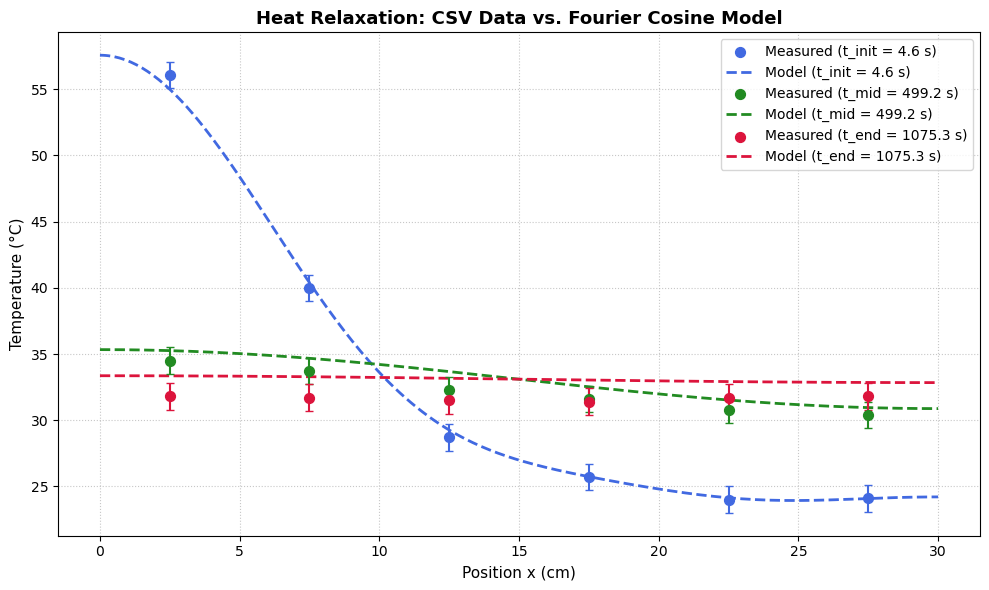

In [2]:
#This code generates the heat equation at t=0 and checks for future times

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. Cosine basis coefficients calculation (from heat_equation.py)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes the cosine expansion coefficients for temperature profile T.
        coeffs[0] = mean temperature (T0)
        coeffs[n] = mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Main CSV Analysis & Model Fitting
# ---------------------------------------------------------
def analyze_heat_diffusion_csv(csv_path, M=5, is_celsius=True, L_m=0.3):
    """
    Reads CSV measurement data, estimates heat parameters, and plots profiles.
    
    Inputs:
        csv_path: Path to CSV file.
        M: Number of cosine modes to sum over.
        is_celsius: True if temperatures are in °C (converts to K), False if in Kelvin.
        L_m: Rod length in meters (default: 0.3 m = 30 cm).
    """
    # Read CSV file using pandas
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm from column headers -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times (col 0) and temperature data (cols 1..N)
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature unit conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # --- Step 1: Compute T0 and C_n from initial measurement (t = t_init) ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]
    
    # --- Step 2: Fit Thermal Diffusivity (alpha) across space & time ---
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    
    def model_func(X_and_T, alpha):
        t_val, x_val = X_and_T
        T_pred = np.full_like(x_val, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha * (k_n**2) * t_val)
            T_pred += b_n * np.cos(k_n * x_val)
        return T_pred

    # Fit alpha using non-linear least squares
    popt, _ = curve_fit(model_func, (times_flat, x_flat), T_measured_flat, p0=[1.0e-4], bounds=(1e-7, 1e-2))
    alpha_fit = popt[0]
    
    # Print fitted constants
    print("=" * 55)
    print(" FITTED HEAT EQUATION PARAMETERS (FROM CSV)")
    print("=" * 55)
    print(f"Equilibrium Temperature (T0): {T0_est:.2f} K ({T0_est - 273.15:.2f} °C)")
    print(f"Thermal Diffusivity (alpha): {alpha_fit:.4e} m^2/s")
    print("-" * 55)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 55)
    
    # --- Step 3: Evaluate model and plot t_init, t_mid, t_end ---
    def eval_model(x_dense, t):
        T_eval = np.full_like(x_dense, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha_fit * (k_n**2) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0
    
    plt.figure(figsize=(10, 6))
    
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.errorbar(x_sensors_cm, T_measured_disp, yerr=1.0, fmt='none', ecolor=color, capsize=3, zorder=4)
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    plt.title("Heat Relaxation: CSV Data vs. Fourier Cosine Model", fontsize=13, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig("S2-no-coeff-exp.png", dpi=300, bbox_inches='tight')
    plt.show()
    # Run analysis on CSV file
if __name__ == "__main__":
    analyze_heat_diffusion_csv("cleaned_data.csv", M=5, is_celsius=True, L_m=0.3)


 GLOBAL FIT RESULTS WITH UNCERTAINTIES (Sensors N = 6, Modes M = 5)
Data Points: 990 | Parameters Fitted: 7 | Degrees of Freedom: 983
---------------------------------------------------------------------------
Equilibrium Temperature (T0):
  Value       : 305.37 K (32.22 °C)
  1-sigma Err : +/- 0.03 K
  95% CI      : [32.16, 32.29] °C
---------------------------------------------------------------------------
Thermal Diffusivity (alpha):
  Value       : 3.4615e-05 m^2/s
  1-sigma Err : +/- 5.8715e-07 m^2/s (1.70%)
  95% CI      : [3.3462e-05, 3.5767e-05] m^2/s
---------------------------------------------------------------------------
Mode C_01: 14.411 +/- 0.166 K  (95% CI: [14.086, 14.736])
Mode C_02: 8.736 +/- 0.250 K  (95% CI: [8.245, 9.228])
Mode C_03: 4.573 +/- 0.374 K  (95% CI: [3.838, 5.307])
Mode C_04: 1.971 +/- 0.527 K  (95% CI: [0.937, 3.006])
Mode C_05: -0.246 +/- 0.714 K  (95% CI: [-1.648, 1.156])


<ipython-input-3-ea9f11f6ae8b>:162: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("S2-with-coeff-exp.png", dpi=300, bbox_inches='tight')
<ipython-input-3-ea9f11f6ae8b>:162: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("S2-with-coeff-exp.png", dpi=300, bbox_inches='tight')


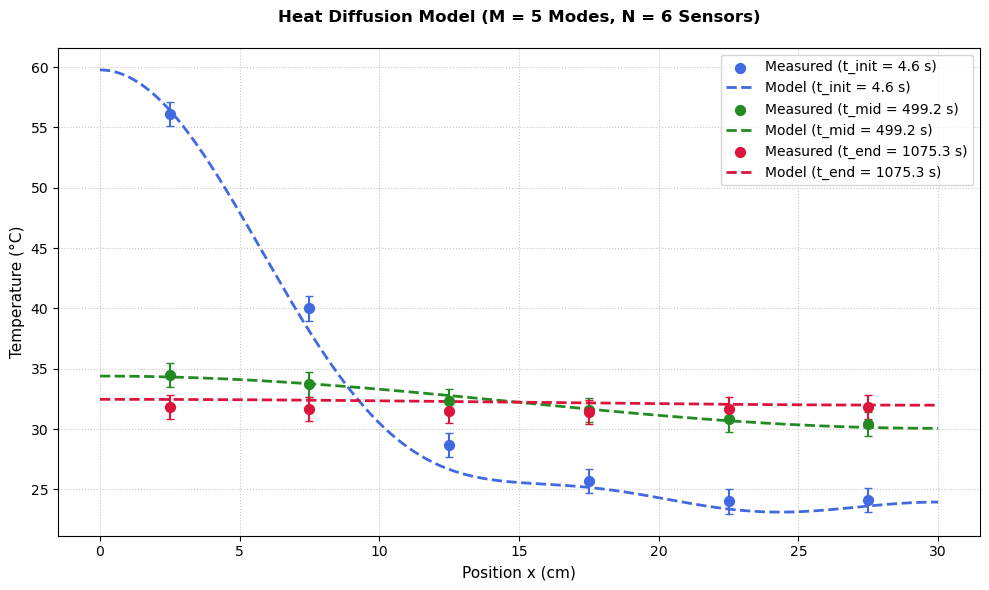

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

def analyze_heat_diffusion_arbitrary_M(csv_path, M=16, is_celsius=True, L_m=0.3):
    """
    Fits heat diffusion parameters T0, C_1..C_M, and alpha simultaneously across space and time.
    Calculates 1-sigma standard errors and 95% confidence intervals for all parameters.
    
    Inputs:
        csv_path: Path to CSV data file.
        M: Number of cosine modes (can be greater than N).
        is_celsius: True if input temps are in °C (converts to K), False if in Kelvin.
        L_m: Rod length in meters (default: 0.3 m = 30 cm).
    """
    # 1. Load CSV data
    df = pd.read_csv(csv_path)
    
    # Sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Times and temperatures
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # 2. Flatten space-time grid for global multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)
    
    # 3. Define multi-parameter target model
    def heat_model_global(X_and_T, T0, *params):
        # params: [C_1, C_2, ..., C_M, alpha]
        C_vec = params[:M]
        alpha = params[M]
        
        t_val, x_val = X_and_T
        T_pred = np.full_like(x_val, T0)
        
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            T_pred += C_vec[n-1] * np.exp(-alpha * (k_n**2) * t_val) * np.cos(k_n * x_val)
        return T_pred

    # Initial guesses & physical bounds
    p0 = [np.mean(T_data_K)] + [0.0] * M + [1.0e-4]
    bounds_lower = [0.0] + [-np.inf] * M + [1.0e-8]
    bounds_upper = [np.inf] + [np.inf] * M + [1.0e-2]
    
    # Perform global optimization and capture covariance matrix pcov
    popt, pcov = curve_fit(
        heat_model_global, 
        (times_flat, x_flat), 
        T_measured_flat, 
        p0=p0, 
        bounds=(bounds_lower, bounds_upper)
    )
    
    # Unpack fitted parameters
    T0_fit = popt[0]
    C_fit = popt[1:M+1]
    alpha_fit = popt[M+1]
    
    # Extract 1-sigma standard errors
    perr = np.sqrt(np.diag(pcov))
    T0_err = perr[0]
    C_err = perr[1:M+1]
    alpha_err = perr[M+1]
    
    # Calculate degrees of freedom and 95% Confidence Intervals
    N_params = len(popt)
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)  # Two-tailed Student's t critical value
    
    T0_ci95 = t_val_crit * T0_err
    C_ci95 = t_val_crit * C_err
    alpha_ci95 = t_val_crit * alpha_err
    
    # Print summary report with statistical uncertainties
    print("=" * 75)
    print(f" GLOBAL FIT RESULTS WITH UNCERTAINTIES (Sensors N = {N_sensors}, Modes M = {M})")
    print("=" * 75)
    print(f"Data Points: {N_data} | Parameters Fitted: {N_params} | Degrees of Freedom: {dof}")
    print("-" * 75)
    print(f"Equilibrium Temperature (T0):")
    print(f"  Value       : {T0_fit:.2f} K ({T0_fit - 273.15:.2f} °C)")
    print(f"  1-sigma Err : +/- {T0_err:.2f} K")
    print(f"  95% CI      : [{T0_fit - T0_ci95 - 273.15:.2f}, {T0_fit + T0_ci95 - 273.15:.2f}] °C")
    print("-" * 75)
    print(f"Thermal Diffusivity (alpha):")
    print(f"  Value       : {alpha_fit:.4e} m^2/s")
    print(f"  1-sigma Err : +/- {alpha_err:.4e} m^2/s ({alpha_err/alpha_fit*100:.2f}%)")
    print(f"  95% CI      : [{alpha_fit - alpha_ci95:.4e}, {alpha_fit + alpha_ci95:.4e}] m^2/s")
    print("-" * 75)
    for n in range(1, M + 1):
        print(f"Mode C_{n:02d}: {C_fit[n-1]:.3f} +/- {C_err[n-1]:.3f} K  (95% CI: [{C_fit[n-1]-C_ci95[n-1]:.3f}, {C_fit[n-1]+C_ci95[n-1]:.3f}])")
    print("=" * 75)
    
    # 4. Dense evaluation for continuous spatial curves
    def eval_model(x_dense, t_val):
        T_eval = np.full_like(x_dense, T0_fit)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_fit[n-1] * np.exp(-alpha_fit * (k_n**2) * t_val)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 400)
    x_dense_cm = x_dense * 100.0
    
    # Plotting
    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.errorbar(x_sensors_cm, T_measured_disp, yerr=1.0, fmt='none', ecolor=color, capsize=3, zorder=4)
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    title_str = (
        f"Heat Diffusion Model (M = {M} Modes, N = {N_sensors} Sensors)\n"
    )
    plt.title(title_str, fontsize=12, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig("S2-with-coeff-exp.png", dpi=300, bbox_inches='tight')
    plt.show()
    


# Run with M = 5 modes on calibrated 6 sensors dataset
if __name__ == "__main__":
    analyze_heat_diffusion_arbitrary_M("cleaned_data.csv", M=5, is_celsius=True, L_m=0.3)


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

def analyze_heat_diffusion_complete(
    csv_path, 
    M=12, 
    is_celsius=True, 
    L_m=0.3, 
    fix_T_env=False, 
    T_env_user_K=293.15
):
    """
    Fits 1D heat diffusion with convective loss:
      T(x, t) = T_env + (T0_init - T_env)*exp(-gamma*t) + sum_{n=1}^M C_n * exp(-(alpha*k_n^2 + gamma)*t) * cos(k_n * x)

    Inputs:
        csv_path     : Path to CSV data file.
        M            : Number of spatial Fourier modes.
        is_celsius   : True if input measurements are in °C, False if in Kelvin.
        L_m          : Rod length in meters (default: 0.3 m = 30 cm).
        fix_T_env    : True to manually fix ambient temperature, False to let curve_fit find it.
        T_env_user_K : Ambient temperature in Kelvin (used when fix_T_env=True).
    """
    # 1. Read CSV File
    df = pd.read_csv(csv_path)
    
    # Sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Times and temperature data
    times = df.iloc[:, 0].values.astype(float)
    T_data_orig = df.iloc[:, 1:].values.astype(float)
    T_data_K = (T_data_orig + 273.15) if is_celsius else T_data_orig.copy()
        
    # Flatten space-time grid for global multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)
    
    # 2. Fit Parameters & Extract Covariance Matrix (pcov)
    if fix_T_env:
        # Fixed Environment Temperature Model
        def heat_model_fixed(X_and_T, T0_init, alpha, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env_user_K + (T0_init - T_env_user_K) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        p0 = [323.15, 1.0e-4, 0.002] + [0.0] * M
        bounds_lower = [290.0, 1.0e-8, 0.0] + [-np.inf] * M
        bounds_upper = [360.0, 1.0e-2, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_fixed, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit = T_env_user_K
        T0_init_fit, alpha_fit, gamma_fit = popt[:3]
        C_fit = popt[3:]
        idx_alpha, idx_gamma = 1, 2

    else:
        # Free Environment Temperature Model (curve_fit optimizes T_env)
        def heat_model_free(X_and_T, T_env, T0_init, alpha, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env + (T0_init - T_env) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        p0 = [293.15, 323.15, 1.0e-4, 0.002] + [0.0] * M
        bounds_lower = [270.0, 290.0, 1.0e-8, 0.0] + [-np.inf] * M
        bounds_upper = [310.0, 360.0, 1.0e-2, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_free, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit, T0_init_fit, alpha_fit, gamma_fit = popt[:4]
        C_fit = popt[4:]
        idx_alpha, idx_gamma = 2, 3

    # 3. Compute Standard Errors & 95% Confidence Intervals
    perr = np.sqrt(np.diag(pcov))  # 1-sigma standard errors
    N_params = len(popt)
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)  # Two-tailed Student's t critical value

    err_alpha = perr[idx_alpha]
    err_gamma = perr[idx_gamma]
    ci95_alpha = t_val_crit * err_alpha
    ci95_gamma = t_val_crit * err_gamma

    # Print Summary Report
    env_status = f"Fixed ({T_env_fit:.2f} K)" if fix_T_env else f"Fitted ({T_env_fit:.2f} K)"
    print("=" * 70)
    print(f" HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: {env_status})")
    print("=" * 70)
    print(f"Thermal Diffusivity (alpha):")
    print(f"  Value       : {alpha_fit:.4e} m^2/s")
    print(f"  1-sigma Err : +/- {err_alpha:.4e} m^2/s ({err_alpha/alpha_fit*100:.2f}%)")
    print(f"  95% CI      : [{alpha_fit - ci95_alpha:.4e}, {alpha_fit + ci95_alpha:.4e}] m^2/s")
    print("-" * 70)
    print(f"Cooling Loss Rate (gamma):")
    print(f"  Value       : {gamma_fit:.4e} 1/s")
    print(f"  1-sigma Err : +/- {err_gamma:.4e} 1/s ({err_gamma/gamma_fit*100:.2f}%)")
    print(f"  95% CI      : [{gamma_fit - ci95_gamma:.4e}, {gamma_fit + ci95_gamma:.4e}] 1/s")
    print("-" * 70)
    print(f"Mean Initial Temp (T0_init): {T0_init_fit - 273.15:.2f} °C")
    if not fix_T_env:
        print(f"Ambient Temp (T_env)       : {T_env_fit - 273.15:.2f} +/- {perr[0]:.2f} °C")
    print("=" * 70)

    # 4. Dense Grid Evaluation & Graph Generation (t_init, t_mid, t_end)
    x_dense = np.linspace(0, L_m, 400)
    x_dense_cm = x_dense * 100.0

    def eval_model(x_dense, t):
        T_eval = T_env_fit + (T0_init_fit - T_env_fit) * np.exp(-gamma_fit * t)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_fit[n-1] * np.exp(-(alpha_fit * (k_n**2) + gamma_fit) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1

    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.0f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.0f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.0f} s",   'crimson')
    ]

    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_orig[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")

    title_str = (
        f"Heat Diffusion with System Loss & Uncertainty Estimation\n"
        f"alpha = ({alpha_fit:.3e} +/- {err_alpha:.3e}) m^2/s,  gamma = ({gamma_fit:.3e} +/- {err_gamma:.3e}) s^-1"
    )
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

 HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: Fitted (305.01 K))
Thermal Diffusivity (alpha):
  Value       : 1.9758e-05 m^2/s
  1-sigma Err : +/- 5.2553e-07 m^2/s (2.66%)
  95% CI      : [1.8727e-05, 2.0790e-05] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 1.5109e-03 1/s
  1-sigma Err : +/- 6.3526e-05 1/s (4.20%)
  95% CI      : [1.3862e-03, 1.6356e-03] 1/s
----------------------------------------------------------------------
Mean Initial Temp (T0_init): 33.55 °C
Ambient Temp (T_env)       : 31.86 +/- 0.05 °C


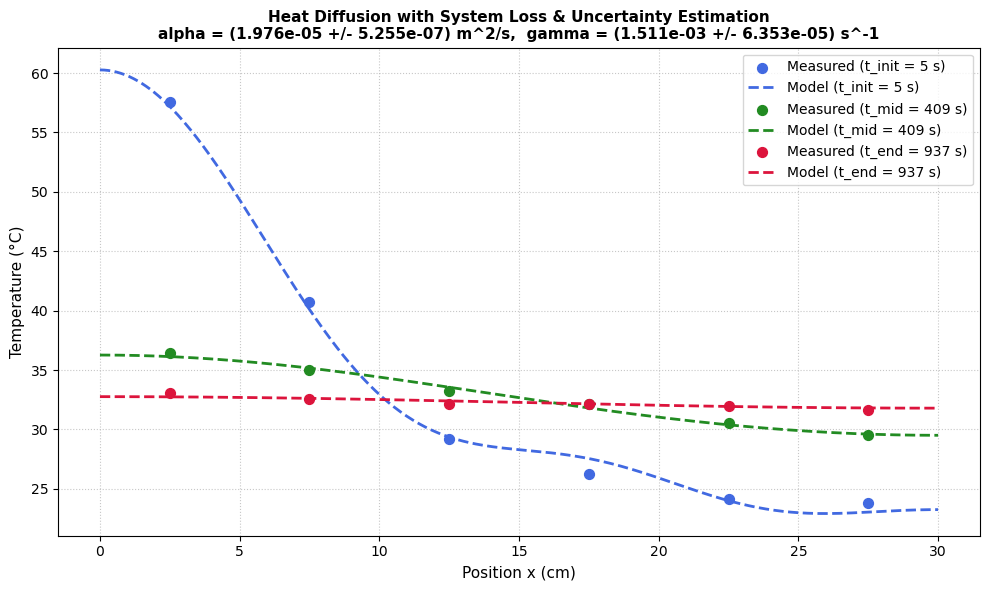

In [30]:
#Analyzing loss without given temperature of environment

analyze_heat_diffusion_complete(
        "heat_measurement_calibrated_6sensors.csv", 
        M=6, 
        is_celsius=True, 
        L_m=0.3, 
        fix_T_env=False)

 HEAT EQUATION FIT RESULTS & UNCERTAINTIES (Env: Fixed (306.00 K))
Thermal Diffusivity (alpha):
  Value       : 1.7208e-05 m^2/s
  1-sigma Err : +/- 7.2309e-07 m^2/s (4.20%)
  95% CI      : [1.5788e-05, 1.8627e-05] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 1.8345e-03 1/s
  1-sigma Err : +/- 8.9212e-05 1/s (4.86%)
  95% CI      : [1.6594e-03, 2.0097e-03] 1/s
----------------------------------------------------------------------
Mean Initial Temp (T0_init): 33.08 °C


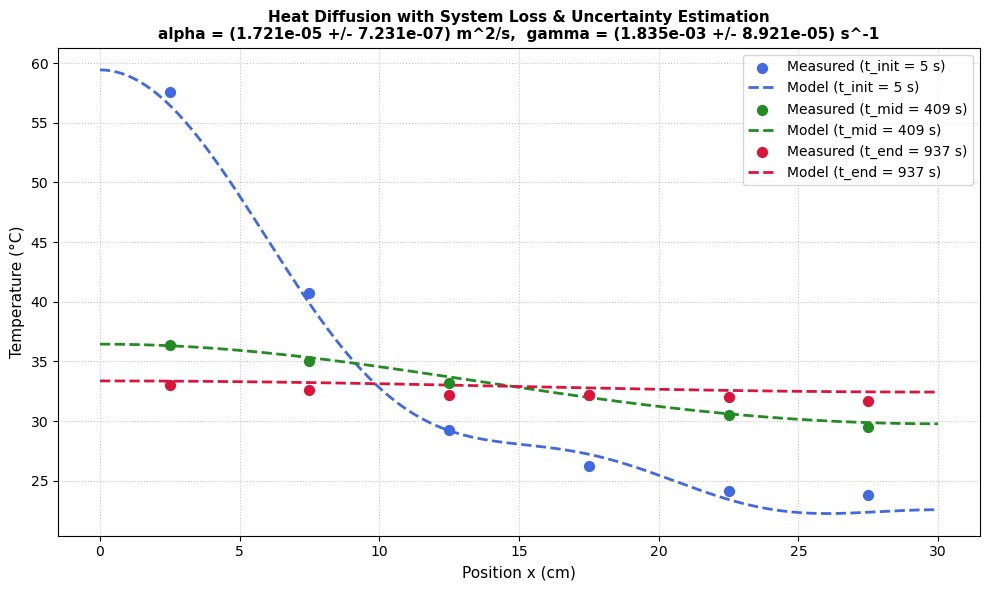

In [32]:
#analyzing loss heat equation WITH given temperature of environment

analyze_heat_diffusion_complete(
        "heat_measurement_calibrated_6sensors.csv", 
        M=6, 
        is_celsius=True, 
        L_m=0.3, 
        fix_T_env=True, 
        T_env_user_K=306
    )

In [30]:
# Calculates only gamma, with alpha given

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

def analyze_heat_diffusion_fixed_alpha(
    csv_path, 
    alpha_given=1.16e-4,  # Thermal diffusivity in m^2/s (FIXED, e.g., 3.4e-5 for brass)
    M=12, 
    is_celsius=True, 
    L_m=0.3, 
    fix_T_env=False, 
    T_env_user_K=293.15
):
    """
    Fits 1D heat diffusion with convective loss when thermal diffusivity alpha is FIXED.
    Calculates standard uncertainty and 95% confidence interval for gamma, and plots
    3 continuous spatial model curves alongside measured sensor points.

    Inputs:
        csv_path     : Path to CSV data file.
        alpha_given  : Thermal diffusivity in m^2/s (FIXED constant, not fitted).
        M            : Number of spatial Fourier modes.
        is_celsius   : True if input measurements are in °C, False if in Kelvin.
        L_m          : Rod length in meters (default: 0.3 m = 30 cm).
        fix_T_env    : True to fix ambient temperature manually, False to let curve_fit find it.
        T_env_user_K : Ambient temperature in Kelvin (used when fix_T_env=True).
    """
    # 1. Read CSV File
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times and temperature data
    times = df.iloc[:, 0].values.astype(float)
    T_data_orig = df.iloc[:, 1:].values.astype(float)
    T_data_K = (T_data_orig + 273.15) if is_celsius else T_data_orig.copy()
        
    # Flatten grid for spatiotemporal multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)
    
    # 2. Define Model & Execute Fit (alpha is held constant)
    if fix_T_env:
        def heat_model_fixed_env(X_and_T, T0_init, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env_user_K + (T0_init - T_env_user_K) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        # Initial parameter guesses: [T0_init, gamma, C_1, ..., C_M]
        p0 = [323.15, 0.002] + [0.0] * M
        bounds_lower = [290.0, 0.0] + [-np.inf] * M
        bounds_upper = [360.0, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_fixed_env, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit = T_env_user_K
        T0_init_fit, gamma_fit = popt[:2]
        C_fit = popt[2:]
        idx_gamma = 1
        idx_C_start = 2

    else:
        def heat_model_free_env(X_and_T, T_env, T0_init, gamma, *C_params):
            t_val, x_val = X_and_T
            T_pred = T_env + (T0_init - T_env) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_params[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred
        
        # Initial parameter guesses: [T_env, T0_init, gamma, C_1, ..., C_M]
        p0 = [293.15, 323.15, 0.002] + [0.0] * M
        bounds_lower = [270.0, 290.0, 0.0] + [-np.inf] * M
        bounds_upper = [310.0, 360.0, 0.1] + [np.inf] * M
        
        popt, pcov = curve_fit(
            heat_model_free_env, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=(bounds_lower, bounds_upper)
        )
        
        T_env_fit, T0_init_fit, gamma_fit = popt[:3]
        C_fit = popt[3:]
        idx_gamma = 2
        idx_C_start = 3

    # 3. Compute Standard Error & 95% Confidence Interval for gamma and C_n
    perr = np.sqrt(np.diag(pcov))  # 1-sigma standard error array
    N_params = len(popt)
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)

    err_gamma = perr[idx_gamma]
    ci95_gamma = t_val_crit * err_gamma
    C_err = perr[idx_C_start:]

    # Print Summary Report
    env_status = f"Fixed ({T_env_fit:.2f} K)" if fix_T_env else f"Fitted ({T_env_fit:.2f} K)"
    print("=" * 70)
    print(f" HEAT EQUATION FIT RESULTS (FIXED ALPHA, Env: {env_status})")
    print("=" * 70)
    print(f"Given Thermal Diffusivity (alpha): {alpha_given:.4e} m^2/s (FIXED)")
    print("-" * 70)
    print(f"Cooling Loss Rate (gamma):")
    print(f"  Fitted Value: {gamma_fit:.4e} 1/s")
    print(f"  1-sigma Err : +/- {err_gamma:.4e} 1/s ({err_gamma/gamma_fit*100:.2f}%)")
    print(f"  95% CI      : [{gamma_fit - ci95_gamma:.4e}, {gamma_fit + ci95_gamma:.4e}] 1/s")
    print("-" * 70)
    print(f"Mean Initial Temp (T0_init): {T0_init_fit - 273.15:.2f} °C")
    if not fix_T_env:
        print(f"Ambient Temp (T_env)       : {T_env_fit - 273.15:.2f} +/- {perr[0]:.2f} °C")
    print("-" * 70)
    print("Fourier Coefficients (C_n):")
    for n in range(1, M + 1):
        print(f"  C_{n:<2d} : {C_fit[n-1]:+.4e} +/- {C_err[n-1]:.4e} K")
    print("=" * 70)

    # 4. Dense Grid Evaluation & Graph Generation (t_init, t_mid, t_end)
    x_dense = np.linspace(0, L_m, 400)
    x_dense_cm = x_dense * 100.0

    def eval_model(x_dense, t):
        T_eval = T_env_fit + (T0_init_fit - T_env_fit) * np.exp(-gamma_fit * t)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_fit[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma_fit) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1

    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.0f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.0f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.0f} s",   'crimson')
    ]

    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_orig[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.errorbar(x_sensors_cm, T_measured_disp, yerr=1.0, fmt='none', ecolor=color, capsize=3, zorder=4)
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")

    title_str = (
        f"Heat Diffusion and loss in closed system"
    )
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig("S8-gamma-exp.png", dpi=300, bbox_inches='tight')
    plt.show()


 HEAT EQUATION FIT RESULTS (FIXED ALPHA, Env: Fitted (310.00 K))
Given Thermal Diffusivity (alpha): 3.2317e-05 m^2/s (FIXED)
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Fitted Value: 7.3613e-04 1/s
  1-sigma Err : +/- 1.9752e-04 1/s (26.83%)
  95% CI      : [3.4774e-04, 1.1245e-03] 1/s
----------------------------------------------------------------------
Mean Initial Temp (T0_init): 43.87 °C
Ambient Temp (T_env)       : 36.85 +/- 1.98 °C
----------------------------------------------------------------------
Fourier Coefficients (C_n):
  C_1  : +1.7813e+01 +/- 5.0533e-01 K
  C_2  : +1.2805e+01 +/- 6.3385e-01 K
  C_3  : +9.6084e+00 +/- 9.3810e-01 K
  C_4  : +5.8671e+00 +/- 1.2867e+00 K
  C_5  : +2.1111e+00 +/- 1.6973e+00 K


<ipython-input-30-22eb99552283>:191: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("S8-gamma-exp.png", dpi=300, bbox_inches='tight')
<ipython-input-30-22eb99552283>:191: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("S8-gamma-exp.png", dpi=300, bbox_inches='tight')


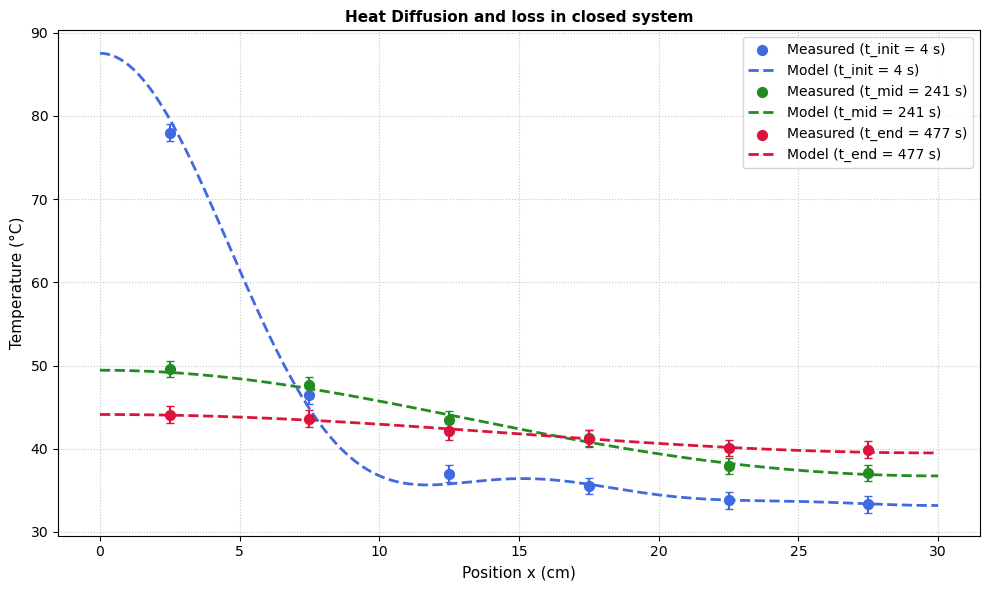

In [31]:
analyze_heat_diffusion_fixed_alpha(
    "cleaned_data8.csv", 
    alpha_given=3.2317e-5,  # Thermal diffusivity in m^2/s (FIXED, e.g., 3.4e-5 for brass)
    M=5, 
    is_celsius=True, 
    L_m=0.3, 
    fix_T_env=False,
    T_env_user_K=296.35
)

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

# ---------------------------------------------------------
# 1. Cosine basis coefficients calculation (at t=0)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes the cosine expansion coefficients for temperature profile T at t=0.
        coeffs[0] = initial mean temperature (T0)
        coeffs[n] = mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Main CSV Analysis, Parameter & Error Fitting
# ---------------------------------------------------------
def analyze_heat_diffusion_csv(
    csv_path, 
    M=5, 
    is_celsius=True, 
    L_m=0.3,
    fix_T_env=False,
    T_env_user_K=293.15
):
    """
    Reads CSV data, calculates initial spatial coefficients at t=0, then fits alpha, gamma,
    and optionally T_env across all (x_i, t_j) measurements. Computes parameter uncertainties
    and plots spatial curves at t_init, t_mid, and t_end.

    Inputs:
        csv_path     : Path to CSV file.
        M            : Number of spatial Fourier modes.
        is_celsius   : True if temperatures are in °C, False if in Kelvin.
        L_m          : Rod length in meters (default: 0.3 m = 30 cm).
        fix_T_env    : True to fix ambient temperature, False to let curve_fit optimize it.
        T_env_user_K : Fixed environment temperature in Kelvin (used if fix_T_env=True).
    """
    # Load CSV data
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm from headers -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract measurement times and temperatures
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    T_data_K = (T_data + 273.15) if is_celsius else T_data.copy()
        
    # --- Step 1: Compute T0 and C_n ONLY from initial measurement (t = 0) ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]
    
    # Grid flattening for multi-variable optimization
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)
    
    # --- Step 2: Fit alpha, gamma (and T_env if fix_T_env=False) ---
    if fix_T_env:
        # Fixed T_env model
        def model_func(X_and_T, alpha, gamma):
            t_val, x_val = X_and_T
            T_pred = T_env_user_K + (T0_est - T_env_user_K) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_n_est[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred

        p0 = [1.0e-4, 1.0e-3]
        bounds = ([1e-7, 0.0], [1e-2, 1.0])
        
        popt, pcov = curve_fit(
            model_func, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=bounds
        )
        
        T_env_fit = T_env_user_K
        alpha_fit, gamma_fit = popt
        perr = np.sqrt(np.diag(pcov))
        err_alpha, err_gamma = perr[0], perr[1]
        err_T_env = 0.0

    else:
        # Free T_env model (curve_fit finds T_env)
        def model_func(X_and_T, T_env, alpha, gamma):
            t_val, x_val = X_and_T
            T_pred = T_env + (T0_est - T_env) * np.exp(-gamma * t_val)
            for n in range(1, M + 1):
                k_n = n * np.pi / L_m
                b_n = C_n_est[n-1] * np.exp(-(alpha * (k_n**2) + gamma) * t_val)
                T_pred += b_n * np.cos(k_n * x_val)
            return T_pred

        p0 = [293.15, 1.0e-4, 1.0e-3]
        bounds = ([270.0, 1e-7, 0.0], [350.0, 1e-2, 1.0])
        
        popt, pcov = curve_fit(
            model_func, 
            (times_flat, x_flat), 
            T_measured_flat, 
            p0=p0, 
            bounds=bounds
        )
        
        T_env_fit, alpha_fit, gamma_fit = popt
        perr = np.sqrt(np.diag(pcov))
        err_T_env, err_alpha, err_gamma = perr[0], perr[1], perr[2]

    # --- Step 3: Compute Uncertainties & 95% Confidence Intervals ---
    N_params = len(popt)
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)  # Two-tailed Student's t critical value (~1.96)
    
    ci95_alpha = t_val_crit * err_alpha
    ci95_gamma = t_val_crit * err_gamma
    ci95_T_env = t_val_crit * err_T_env

    # Print Summary Report
    env_status = f"Fixed ({T_env_fit:.2f} K)" if fix_T_env else f"Fitted ({T_env_fit:.2f} K)"
    print("=" * 70)
    print(f" FITTED PARAMETERS WITH UNCERTAINTIES ({env_status})")
    print("=" * 70)
    print(f"Data Points: {N_data} | Parameters Fitted: {N_params} | Degrees of Freedom: {dof}")
    print("-" * 70)
    print(f"Thermal Diffusivity (alpha):")
    print(f"  Value       : {alpha_fit:.4e} m^2/s")
    print(f"  1-sigma Err : +/- {err_alpha:.4e} m^2/s ({err_alpha/alpha_fit*100:.2f}%)")
    print(f"  95% CI      : [{alpha_fit - ci95_alpha:.4e}, {alpha_fit + ci95_alpha:.4e}] m^2/s")
    print("-" * 70)
    print(f"Cooling Loss Rate (gamma):")
    print(f"  Value       : {gamma_fit:.4e} 1/s")
    print(f"  1-sigma Err : +/- {err_gamma:.4e} 1/s ({err_gamma/gamma_fit*100:.2f}%)")
    print(f"  95% CI      : [{gamma_fit - ci95_gamma:.4e}, {gamma_fit + ci95_gamma:.4e}] 1/s")
    print("-" * 70)
    print(f"Initial Mean Temp (T0 at t=0): {T0_est - 273.15:.2f} °C ({T0_est:.2f} K)")
    if fix_T_env:
        print(f"Ambient Temp (T_env)         : {T_env_fit - 273.15:.2f} °C (Fixed)")
    else:
        print(f"Ambient Temp (T_env)         : {T_env_fit - 273.15:.2f} +/- {err_T_env:.2f} °C")
        print(f"  95% CI                     : [{T_env_fit - ci95_T_env - 273.15:.2f}, {T_env_fit + ci95_T_env - 273.15:.2f}] °C")
    print("-" * 70)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 70)

    # --- Step 4: Evaluate model and plot t_init, t_mid, t_end ---
    def eval_model(x_dense, t_val):
        T_eval = T_env_fit + (T0_est - T_env_fit) * np.exp(-gamma_fit * t_val)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-(alpha_fit * (k_n**2) + gamma_fit) * t_val)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0
    
    plt.figure(figsize=(10, 6))
    
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    title_str = (
        f"Heat Diffusion with System Loss & Uncertainty Calculation\n"
        f"alpha = ({alpha_fit:.3e} +/- {err_alpha:.3e}) m^2/s,  gamma = ({gamma_fit:.3e} +/- {err_gamma:.3e}) s^-1"
    )
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# Example Execution
# ---------------------------------------------------------


 FITTED PARAMETERS WITH UNCERTAINTIES (Fitted (304.86 K))
Data Points: 780 | Parameters Fitted: 3 | Degrees of Freedom: 777
----------------------------------------------------------------------
Thermal Diffusivity (alpha):
  Value       : 2.0747e-05 m^2/s
  1-sigma Err : +/- 4.1024e-07 m^2/s (1.98%)
  95% CI      : [1.9942e-05, 2.1553e-05] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 1.3662e-03 1/s
  1-sigma Err : +/- 4.9500e-05 1/s (3.62%)
  95% CI      : [1.2690e-03, 1.4633e-03] 1/s
----------------------------------------------------------------------
Initial Mean Temp (T0 at t=0): 33.61 °C (306.76 K)
Ambient Temp (T_env)         : 31.71 +/- 0.05 °C
  95% CI                     : [31.61, 31.81] °C
----------------------------------------------------------------------
Mode n=1 Amplitude (C_1): 15.046 K
Mode n=2 Amplitude (C_2): 7.473 K
Mode n=3 Amplitude (C_3): 3.320 K
Mode n=4 Amplitude (C_4): 1.177 K
Mode n

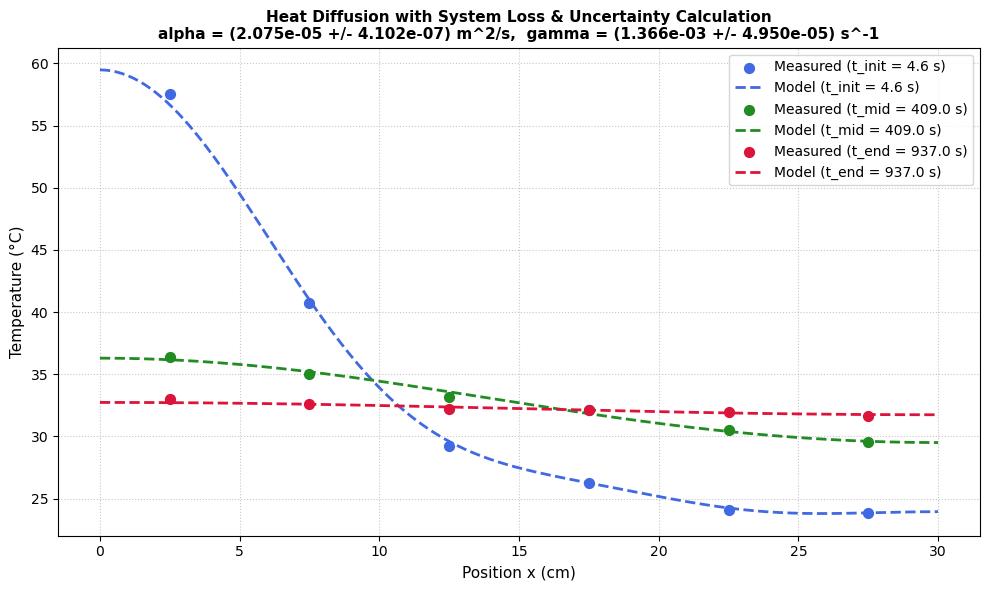

 FITTED PARAMETERS WITH UNCERTAINTIES (Fixed (300.00 K))
Data Points: 780 | Parameters Fitted: 2 | Degrees of Freedom: 778
----------------------------------------------------------------------
Thermal Diffusivity (alpha):
  Value       : 2.9828e-05 m^2/s
  1-sigma Err : +/- 1.7856e-07 m^2/s (0.60%)
  95% CI      : [2.9478e-05, 3.0179e-05] m^2/s
----------------------------------------------------------------------
Cooling Loss Rate (gamma):
  Value       : 2.7855e-04 1/s
  1-sigma Err : +/- 5.4454e-06 1/s (1.95%)
  95% CI      : [2.6786e-04, 2.8924e-04] 1/s
----------------------------------------------------------------------
Initial Mean Temp (T0 at t=0): 33.61 °C (306.76 K)
Ambient Temp (T_env)         : 26.85 °C (Fixed)
----------------------------------------------------------------------
Mode n=1 Amplitude (C_1): 15.046 K
Mode n=2 Amplitude (C_2): 7.473 K
Mode n=3 Amplitude (C_3): 3.320 K
Mode n=4 Amplitude (C_4): 1.177 K
Mode n=5 Amplitude (C_5): -0.047 K


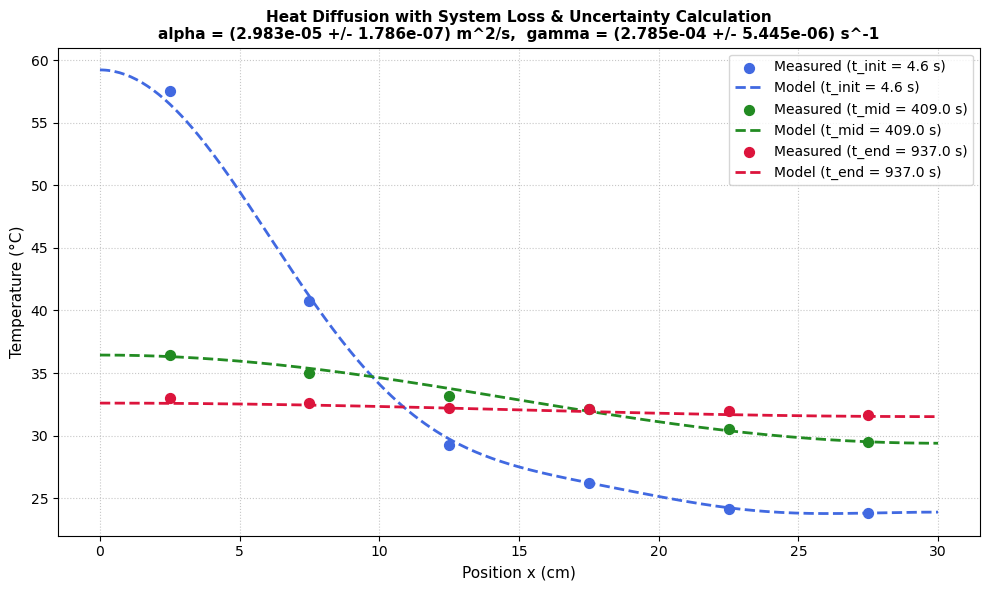

In [37]:
    # Case 1: Let curve_fit find T_env automatically
    analyze_heat_diffusion_csv(
        "heat_measurement_calibrated_6sensors.csv", 
        M=5, 
        is_celsius=True, 
        L_m=0.3, 
        fix_T_env=False
    )
    
    # se 2: Fix T_env manually (e.g., 293.15 K = 20.0 °C)
    analyze_heat_diffusion_csv(
    "heat_measurement_calibrated_6sensors.csv", 
    M=5, 
    is_celsius=True, 
    L_m=0.3, 
    fix_T_env=True, 
    T_env_user_K=300
    )

In [23]:
#verify predictions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Cosine basis coefficients calculation (at t=0)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes the cosine expansion coefficients for temperature profile T at t=0.
        coeffs[0] = mean temperature (T0)
        coeffs[n] = mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Forward Heat Diffusion Evaluation & Plotting
# ---------------------------------------------------------
def analyze_heat_diffusion_given_alpha(
    csv_path, 
    alpha_given=1.16e-4,  # Given thermal diffusivity in m^2/s
    M=5, 
    is_celsius=True, 
    L_m=0.3
):
    """
    Reads CSV measurement data, transforms the initial temperature profile at t=0 
    into Fourier cosine coefficients (T0, C_1..C_M), and projects heat relaxation 
    forward in time using a given thermal diffusivity (alpha_given).
    
    Inputs:
        csv_path: Path to CSV data file.
        alpha_given: Fixed thermal diffusivity in m^2/s (e.g., 1.16e-4 for copper).
        M: Number of cosine modes to sum over.
        is_celsius: True if temperatures are in °C (converts to K), False if in Kelvin.
        L_m: Rod length in meters (default: 0.3 m = 30 cm).
    """
    # 1. Read CSV file using pandas
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm from column headers -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times (col 0) and temperature data (cols 1..N)
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature unit conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # --- Step 1: Transform initial temperature profile (t=0) into Fourier basis ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]
    
    # Print calculated Fourier coefficients
    print("=" * 55)
    print(" INITIAL FOURIER TRANSFORM & FORWARD MODEL PARAMETERS")
    print("=" * 55)
    print(f"Equilibrium Temperature (T0): {T0_est:.2f} K ({T0_est - 273.15:.2f} °C)")
    print(f"Given Thermal Diffusivity (alpha): {alpha_given:.4e} m^2/s")
    print("-" * 55)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 55)
    
    # --- Step 2: Forward evaluation function using analytical Fourier solution ---
    def eval_model(x_dense, t):
        T_eval = np.full_like(x_dense, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha_given * (k_n**2) * t)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    # --- Step 3: Plot t_init, t_mid, t_end ---
    idx_init = 0
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0
    
    plt.figure(figsize=(10, 6))
    
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        # Scatter plot for measured points
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        # Dashed line plot for forward model prediction
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    plt.title(f"Heat Relaxation: Forward Fourier Model (alpha = {alpha_given:.2e} m²/s)", fontsize=13, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# Execution Example
# ---------------------------------------------------------


 INITIAL FOURIER TRANSFORM & FORWARD MODEL PARAMETERS
Equilibrium Temperature (T0): 304.23 K (31.08 °C)
Given Thermal Diffusivity (alpha): 3.2300e-05 m^2/s
-------------------------------------------------------
Mode n=1 Amplitude (C_1): 19.354 K
Mode n=2 Amplitude (C_2): 13.250 K
Mode n=3 Amplitude (C_3): 7.000 K
Mode n=4 Amplitude (C_4): 3.183 K
Mode n=5 Amplitude (C_5): 1.181 K


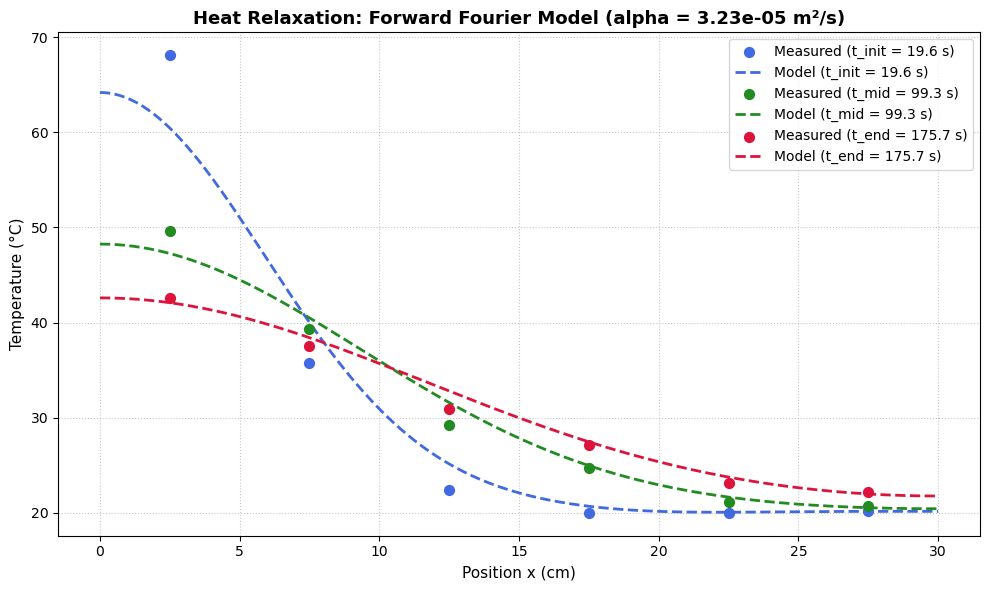

In [24]:
    analyze_heat_diffusion_given_alpha(
        "cleaned_data.csv", 
        alpha_given=3.23e-5,  # Specify your material alpha (m^2/s)
        M=5, 
        is_celsius=True, 
        L_m=0.3)

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Cosine basis coefficients calculation (at t=0)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes the cosine expansion coefficients for temperature profile T at t=0.
        coeffs[0] = initial mean temperature (T0)
        coeffs[n] = mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Forward Heat Model with Mid/End Point Difference Metrics
# ---------------------------------------------------------
def analyze_heat_diffusion_given_alpha(
    csv_path, 
    alpha_given=1.16e-4,  # Fixed thermal diffusivity in m^2/s
    M=5, 
    is_celsius=True, 
    L_m=0.3
):
    """
    Reads CSV measurement data, transforms the initial temperature profile at t=0 
    into Fourier cosine coefficients (T0, C_1..C_M), and projects heat relaxation 
    forward in time using a given thermal diffusivity (alpha_given).

    Calculates the average and maximal absolute difference between model predictions
    and sensor measurements at middle time (t_mid) and end time (t_end).
    """
    # 1. Read CSV file using pandas
    df = pd.read_csv(csv_path)
    
    # Extract x sensor positions in cm from column headers -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times (col 0) and temperature data (cols 1..N)
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    
    # Temperature unit conversion to Kelvin
    if is_celsius:
        T_data_K = T_data + 273.15
    else:
        T_data_K = T_data.copy()
        
    # --- Step 1: Transform initial temperature profile (t=0) into Fourier basis ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]
    
    # Print calculated Fourier coefficients
    print("=" * 65)
    print(" INITIAL FOURIER TRANSFORM & FORWARD MODEL PARAMETERS")
    print("=" * 65)
    print(f"Equilibrium Temperature (T0): {T0_est:.2f} K ({T0_est - 273.15:.2f} °C)")
    print(f"Given Thermal Diffusivity (alpha): {alpha_given:.4e} m^2/s")
    print("-" * 65)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 65)
    
    # --- Step 2: Evaluation functions ---
    def eval_model_at_sensors(t_val):
        """Evaluates model specifically at discrete sensor locations."""
        T_eval = np.full(N_sensors, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha_given * (k_n**2) * t_val)
            T_eval += b_n * np.cos(k_n * x_sensors_m)
        return T_eval

    def eval_model_dense(x_dense, t_val):
        """Evaluates model along a dense spatial grid for smooth curve plotting."""
        T_eval = np.full_like(x_dense, T0_est)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-alpha_given * (k_n**2) * t_val)
            T_eval += b_n * np.cos(k_n * x_dense)
        return T_eval

    # --- Step 3: Calculate Average & Maximal Differences at t_mid and t_end ---
    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    t_mid = times[idx_mid]
    t_end = times[idx_end]
    
    # Middle Time Differences
    T_meas_mid = T_data_K[idx_mid, :]
    T_model_mid = eval_model_at_sensors(t_mid)
    diff_mid = np.abs(T_meas_mid - T_model_mid)
    avg_diff_mid = np.mean(diff_mid)
    max_diff_mid = np.max(diff_mid)
    
    # End Time Differences
    T_meas_end = T_data_K[idx_end, :]
    T_model_end = eval_model_at_sensors(t_end)
    diff_end = np.abs(T_meas_end - T_model_end)
    avg_diff_end = np.mean(diff_end)
    max_diff_end = np.max(diff_end)
    
    # Print Discrepancy Summary
    unit_str = "°C" if is_celsius else "K"
    print(" MODEL VS MEASUREMENT DIFFERENCES")
    print("=" * 65)
    print(f"Middle Time (t_mid = {t_mid:.1f} s):")
    print(f"  Average Absolute Difference : {avg_diff_mid:.3f} {unit_str}")
    print(f"  Maximal Absolute Difference : {max_diff_mid:.3f} {unit_str}")
    print("-" * 65)
    print(f"End Time (t_end = {t_end:.1f} s):")
    print(f"  Average Absolute Difference : {avg_diff_end:.3f} {unit_str}")
    print(f"  Maximal Absolute Difference : {max_diff_end:.3f} {unit_str}")
    print("=" * 65)

    # --- Step 4: Plot t_init, t_mid, t_end ---
    idx_init = 0
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]
    
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0
    
    plt.figure(figsize=(10, 6))
    
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model_dense(x_dense, t_val)
        
        if is_celsius:
            T_measured_disp = T_measured - 273.15
            T_smooth_disp = T_smooth - 273.15
            y_label = "Temperature (°C)"
        else:
            T_measured_disp = T_measured
            T_smooth_disp = T_smooth
            y_label = "Temperature (K)"
            
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.errorbar(x_sensors_cm, T_measured_disp, yerr=1.0, fmt='none', ecolor=color, capsize=3, zorder=4)
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Model ({label})")
        
    title_str = f"Comparison of modelled prediction with measurements for alpha"
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig("S6-pred-exp.png", dpi=300, bbox_inches='tight')
    plt.show()

# ---------------------------------------------------------
# Execution Example
# ---------------------------------------------------------


 INITIAL FOURIER TRANSFORM & FORWARD MODEL PARAMETERS
Equilibrium Temperature (T0): 304.23 K (31.08 °C)
Given Thermal Diffusivity (alpha): 3.2300e-05 m^2/s
-----------------------------------------------------------------
Mode n=1 Amplitude (C_1): 19.354 K
Mode n=2 Amplitude (C_2): 13.250 K
Mode n=3 Amplitude (C_3): 7.000 K
Mode n=4 Amplitude (C_4): 3.183 K
Mode n=5 Amplitude (C_5): 1.181 K
 MODEL VS MEASUREMENT DIFFERENCES
Middle Time (t_mid = 99.3 s):
  Average Absolute Difference : 1.151 °C
  Maximal Absolute Difference : 2.394 °C
-----------------------------------------------------------------
End Time (t_end = 175.7 s):
  Average Absolute Difference : 0.760 °C
  Maximal Absolute Difference : 1.901 °C


<ipython-input-7-6c1977e504e0>:166: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("S6-pred-exp.png", dpi=300, bbox_inches='tight')
<ipython-input-7-6c1977e504e0>:166: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("S6-pred-exp.png", dpi=300, bbox_inches='tight')


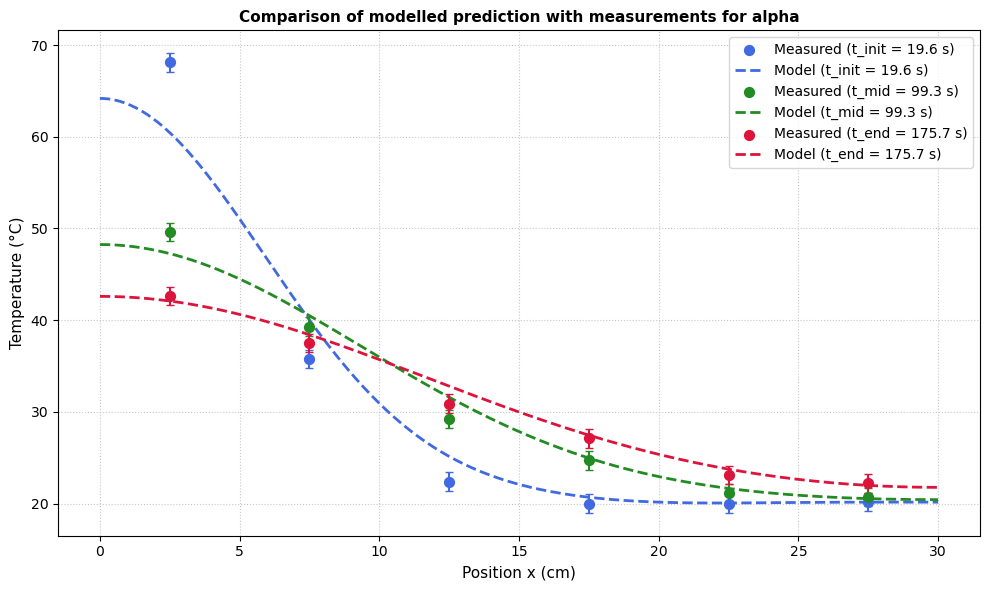

In [8]:
analyze_heat_diffusion_given_alpha(
        "cleaned_data6.csv", 
        alpha_given=3.23e-5,  # Thermal diffusivity (m^2/s)
        M=5, 
        is_celsius=True, 
        L_m=0.3
    )

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

# ---------------------------------------------------------
# 1. Cosine Basis Expansion (Evaluated at t_init ONLY)
# ---------------------------------------------------------
def get_coeffs_cos_basis(T, x, L):
    """
    Computes initial spatial Fourier coefficients for temperature profile T at t=0.
        coeffs[0] = initial mean temperature (T0_init)
        coeffs[n] = initial mode n amplitude (C_n)
    """
    N = len(x)
    coeffs = np.zeros(N)
    coeffs[0] = (1.0 / N) * np.sum(T)
    for n in range(1, N):
        coeffs[n] = (2.0 / N) * np.sum(T * np.cos(n * np.pi / L * x))
    return coeffs

# ---------------------------------------------------------
# 2. Forward Prediction with Fitted T_env & Discrepancy Evaluation
# ---------------------------------------------------------
def predict_and_fit_Tenv_heat_diffusion(
    csv_path, 
    alpha_given=1.16e-4,  # Given thermal diffusivity in m^2/s (FIXED)
    gamma_given=2.50e-3,  # Given cooling loss rate in 1/s (FIXED)
    M=5, 
    is_celsius=True, 
    L_m=0.3
):
    """
    1. Derives Fourier coefficients (T0_init, C_1..C_M) strictly from initial measurement at t=0.
    2. Optimizes T_env automatically across the space-time measurement grid using curve_fit.
    3. Calculates average and maximal absolute deviations between prediction and data at t_mid and t_end.
    """
    # Load CSV data
    df = pd.read_csv(csv_path)
    
    # Extract sensor positions in cm -> convert to meters
    x_sensors_cm = np.array([float(col) for col in df.columns[1:]])
    x_sensors_m = x_sensors_cm / 100.0
    N_sensors = len(x_sensors_m)
    
    # Extract times and measured temperatures
    times = df.iloc[:, 0].values.astype(float)
    T_data = df.iloc[:, 1:].values.astype(float)
    T_data_K = (T_data + 273.15) if is_celsius else T_data.copy()

    # --- Step 1: Fourier Analysis at t_init (t = 0) ONLY ---
    T_init = T_data_K[0, :]
    initial_coeffs = get_coeffs_cos_basis(T_init, x_sensors_m, L_m)
    
    T0_est = initial_coeffs[0]
    C_n_est = initial_coeffs[1:M+1]

    # --- Step 2: Fit T_env across all (x_i, t_j) data points ---
    T_grid, X_grid = np.meshgrid(times, x_sensors_m, indexing='ij')
    times_flat = T_grid.flatten()
    x_flat = X_grid.flatten()
    T_measured_flat = T_data_K.flatten()
    N_data = len(T_measured_flat)

    def model_func_Tenv(X_and_T, T_env):
        t_val, x_val = X_and_T
        T_pred = T_env + (T0_est - T_env) * np.exp(-gamma_given * t_val)
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma_given) * t_val)
            T_pred += b_n * np.cos(k_n * x_val)
        return T_pred

    # Fit single parameter T_env via non-linear least squares
    popt, pcov = curve_fit(
        model_func_Tenv, 
        (times_flat, x_flat), 
        T_measured_flat, 
        p0=[293.15], 
        bounds=(250.0, 350.0)
    )
    
    T_env_fit_K = popt[0]
    perr = np.sqrt(np.diag(pcov))
    err_T_env = perr[0]
    
    # Degrees of freedom & 95% Confidence Interval for T_env
    N_params = 1
    dof = max(1, N_data - N_params)
    t_val_crit = t.ppf(0.975, dof)
    ci95_T_env = t_val_crit * err_T_env

    unit_str = "°C" if is_celsius else "K"
    T_env_fit_disp = T_env_fit_K - 273.15 if is_celsius else T_env_fit_K

    # Print fitted parameter report
    print("=" * 65)
    print(" FOURIER COEFFICIENTS AT t = 0 & FITTED T_ENV RESULT")
    print("=" * 65)
    print(f"Initial Mean Temp (T0_init): {T0_est:.2f} K ({T0_est - 273.15:.2f} °C)")
    print(f"Given Alpha                : {alpha_given:.4e} m^2/s (FIXED)")
    print(f"Given Gamma                : {gamma_given:.4e} s^-1 (FIXED)")
    print("-" * 65)
    print(f"FITTED Ambient Temp (T_env): {T_env_fit_disp:.2f} +/- {err_T_env:.2f} {unit_str} ({T_env_fit_K:.2f} K)")
    print(f"  95% Confidence Interval  : [{T_env_fit_disp - ci95_T_env:.2f}, {T_env_fit_disp + ci95_T_env:.2f}] {unit_str}")
    print("-" * 65)
    for n in range(1, M + 1):
        print(f"Mode n={n} Amplitude (C_{n}): {C_n_est[n-1]:.3f} K")
    print("=" * 65)

    # --- Step 3: Compute Average & Maximal Deviations at t_mid and t_end ---
    def eval_model_at_sensors(t_val):
        T_pred = np.full(N_sensors, T_env_fit_K + (T0_est - T_env_fit_K) * np.exp(-gamma_given * t_val))
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma_given) * t_val)
            T_pred += b_n * np.cos(k_n * x_sensors_m)
        return T_pred

    idx_mid = len(times) // 2
    idx_end = len(times) - 1
    
    t_mid = times[idx_mid]
    t_end = times[idx_end]
    
    # Middle Time Deviations
    T_meas_mid = T_data_K[idx_mid, :]
    T_pred_mid = eval_model_at_sensors(t_mid)
    diff_mid = np.abs(T_meas_mid - T_pred_mid)
    avg_diff_mid = np.mean(diff_mid)
    max_diff_mid = np.max(diff_mid)
    
    # End Time Deviations
    T_meas_end = T_data_K[idx_end, :]
    T_pred_end = eval_model_at_sensors(t_end)
    diff_end = np.abs(T_meas_end - T_pred_end)
    avg_diff_end = np.mean(diff_end)
    max_diff_end = np.max(diff_end)
    
    # Print Discrepancy Report
    print(" PREDICTION VS MEASUREMENT DEVIATION REPORT")
    print("=" * 65)
    print(f"Middle Time (t_mid = {t_mid:.1f} s):")
    print(f"  Average Absolute Deviation : {avg_diff_mid:.3f} {unit_str}")
    print(f"  Maximal Absolute Deviation : {max_diff_mid:.3f} {unit_str}")
    print("-" * 65)
    print(f"End Time (t_end = {t_end:.1f} s):")
    print(f"  Average Absolute Deviation : {avg_diff_end:.3f} {unit_str}")
    print(f"  Maximal Absolute Deviation : {max_diff_end:.3f} {unit_str}")
    print("=" * 65)

    # --- Step 4: Visualizations ---
    x_dense = np.linspace(0, L_m, 300)
    x_dense_cm = x_dense * 100.0

    def eval_model_dense(x_dense, t_val):
        T_pred = np.full_like(x_dense, T_env_fit_K + (T0_est - T_env_fit_K) * np.exp(-gamma_given * t_val))
        for n in range(1, M + 1):
            k_n = n * np.pi / L_m
            b_n = C_n_est[n-1] * np.exp(-(alpha_given * (k_n**2) + gamma_given) * t_val)
            T_pred += b_n * np.cos(k_n * x_dense)
        return T_pred

    idx_init = 0
    time_points = [
        (idx_init, f"t_init = {times[idx_init]:.1f} s", 'royalblue'),
        (idx_mid,  f"t_mid = {times[idx_mid]:.1f} s",   'forestgreen'),
        (idx_end,  f"t_end = {times[idx_end]:.1f} s",   'crimson')
    ]

    plt.figure(figsize=(10, 6))
    for idx, label, color in time_points:
        t_val = times[idx]
        T_measured = T_data_K[idx, :]
        T_smooth = eval_model_dense(x_dense, t_val)
        
        T_measured_disp = (T_measured - 273.15) if is_celsius else T_measured
        T_smooth_disp = (T_smooth - 273.15) if is_celsius else T_smooth
        
        plt.scatter(x_sensors_cm, T_measured_disp, color=color, s=50, zorder=5, label=f"Measured ({label})")
        plt.errorbar(x_sensors_cm, T_measured_disp, yerr=1.0, fmt='none', ecolor=color, capsize=3, zorder=4)
        plt.plot(x_dense_cm, T_smooth_disp, color=color, linewidth=2, linestyle='--', label=f"Prediction ({label})")

    y_label = "Temperature (°C)" if is_celsius else "Temperature (K)"
    title_str = (
        f"Comparison of modelled prediction with measurements for alpha and gamma"
    )
    plt.title(title_str, fontsize=11, fontweight='bold')
    plt.xlabel("Position x (cm)", fontsize=11)
    plt.ylabel(y_label, fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig("S8-pred-gamma-exp.png", dpi=300, bbox_inches='tight')
    plt.show()

# ---------------------------------------------------------
# Execution Example
# ---------------------------------------------------------



 FOURIER COEFFICIENTS AT t = 0 & FITTED T_ENV RESULT
Initial Mean Temp (T0_init): 317.15 K (44.00 °C)
Given Alpha                : 3.2300e-05 m^2/s (FIXED)
Given Gamma                : 1.5100e-03 s^-1 (FIXED)
-----------------------------------------------------------------
FITTED Ambient Temp (T_env): 39.77 +/- 0.40 °C (312.92 K)
  95% Confidence Interval  : [38.98, 40.56] °C
-----------------------------------------------------------------
Mode n=1 Amplitude (C_1): 17.492 K
Mode n=2 Amplitude (C_2): 11.201 K
Mode n=3 Amplitude (C_3): 7.212 K
Mode n=4 Amplitude (C_4): 3.900 K
Mode n=5 Amplitude (C_5): 1.370 K
 PREDICTION VS MEASUREMENT DEVIATION REPORT
Middle Time (t_mid = 241.0 s):
  Average Absolute Deviation : 0.892 °C
  Maximal Absolute Deviation : 1.666 °C
-----------------------------------------------------------------
End Time (t_end = 477.0 s):
  Average Absolute Deviation : 0.465 °C
  Maximal Absolute Deviation : 0.748 °C


<ipython-input-11-78fea9ca4d3a>:195: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("S8-pred-gamma-exp.png", dpi=300, bbox_inches='tight')
<ipython-input-11-78fea9ca4d3a>:195: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("S8-pred-gamma-exp.png", dpi=300, bbox_inches='tight')


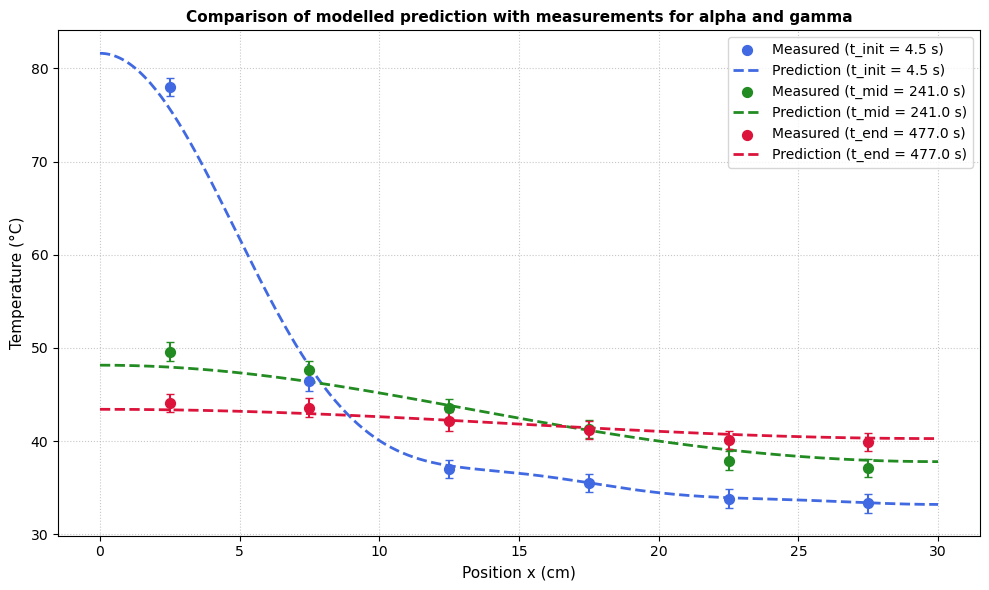

In [12]:
predict_and_fit_Tenv_heat_diffusion(
        "cleaned_data8.csv", 
        alpha_given=3.23e-5,  # Given thermal diffusivity (m^2/s)
        gamma_given=1.51e-3,  # Given cooling loss rate constant (1/s)
        M=5, 
        is_celsius=True, 
        L_m=0.3
    )